In [1]:
print("="*70)
print("Clinical Trial Attrition Prediction")
print("="*70)

Clinical Trial Attrition Prediction


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

In [3]:
df = pd.read_csv("r_and_d_healthcare_clinical_trial_attrition_80k.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (80000, 10)


In [4]:
print("First Five Records:")
df.head()

First Five Records:


,Patient_ID,Clinical_Site_ID,Therapeutic_Area,Patient_Age,Income_Bracket,Distance_to_Site_Miles,Reported_Side_Effect_Score,Early_Missed_Visits,Dropout_Probability_Pct,Study_Outcome_Status
0,PT_TRIAL_000001,CLINIC_24,Neurology,24,High_Income,7.1,3.1,0,23.2,Completed_Study
1,PT_TRIAL_000002,CLINIC_20,Cardiology,57,High_Income,41.1,8.0,0,58.3,Completed_Study
2,PT_TRIAL_000003,CLINIC_38,Dermatology,53,Middle_Income,12.1,1.8,0,31.1,Completed_Study
3,PT_TRIAL_000004,CLINIC_11,Oncology,43,Low_Income,56.7,4.0,0,63.4,At_Risk_Requires_Intervention
4,PT_TRIAL_000005,CLINIC_17,Dermatology,66,Middle_Income,48.7,6.8,0,87.6,Dropped_Out_Toxicity


In [5]:
print("Column Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

Column Names:
Index(['Patient_ID', 'Clinical_Site_ID', 'Therapeutic_Area', 'Patient_Age',
       'Income_Bracket', 'Distance_to_Site_Miles',
       'Reported_Side_Effect_Score', 'Early_Missed_Visits',
       'Dropout_Probability_Pct', 'Study_Outcome_Status'],
      dtype='object')

Data Types:
Patient_ID                     object
Clinical_Site_ID               object
Therapeutic_Area               object
Patient_Age                     int64
Income_Bracket                 object
Distance_to_Site_Miles        float64
Reported_Side_Effect_Score    float64
Early_Missed_Visits             int64
Dropout_Probability_Pct       float64
Study_Outcome_Status           object
dtype: object

Missing Values:
Patient_ID                    0
Clinical_Site_ID              0
Therapeutic_Area              0
Patient_Age                   0
Income_Bracket                0
Distance_to_Site_Miles        0
Reported_Side_Effect_Score    0
Early_Missed_Visits           0
Dropout_Probability_Pct       0
Study_

In [29]:
print("Unique Study Outcome Status:")
print(df["Study_Outcome_Status"].unique())

print("\nCount of Study Outcome Status:")
print(df["Study_Outcome_Status"].value_counts())

Unique Study Outcome Status:
['Completed_Study' 'At_Risk_Requires_Intervention' 'Dropped_Out_Toxicity'
 'Dropped_Out_Logistics']

Count of Study Outcome Status:
Study_Outcome_Status
Completed_Study                  59327
At_Risk_Requires_Intervention    11371
Dropped_Out_Logistics             4655
Dropped_Out_Toxicity              4647
Name: count, dtype: int64


In [6]:
print("\nClass Imbalance Observation:")
print("The target variable contains four different classes.")
print("Therefore, this is a multiclass classification problem.")
print("The target classes are not equally distributed.")
print("Completed Study is the majority class.")
print("The dropout classes have fewer samples than the majority class.")
print("This class imbalance may cause the model to be biased toward the majority class.")
print("Therefore, class imbalance will be considered during model training.")


Class Imbalance Observation:
The target variable contains four different classes.
Therefore, this is a multiclass classification problem.
The target classes are not equally distributed.
Completed Study is the majority class.
The dropout classes have fewer samples than the majority class.
This class imbalance may cause the model to be biased toward the majority class.
Therefore, class imbalance will be considered during model training.


In [7]:
print("Summary Statistics:")
print(df.describe())

Summary Statistics:
        Patient_Age  Distance_to_Site_Miles  Reported_Side_Effect_Score  \
count  80000.000000            80000.000000                80000.000000   
mean      54.881437               30.120766                    3.777218   
std       14.635543               21.283691                    2.288607   
min       18.000000                1.000000                    0.000000   
25%       45.000000               14.600000                    2.100000   
50%       55.000000               25.200000                    3.600000   
75%       65.000000               40.500000                    5.300000   
max       85.000000              246.200000                   10.000000   

       Early_Missed_Visits  Dropout_Probability_Pct  
count         80000.000000             80000.000000  
mean              0.419700                47.132405  
std               0.722605                20.512115  
min               0.000000                 1.000000  
25%               0.000000        

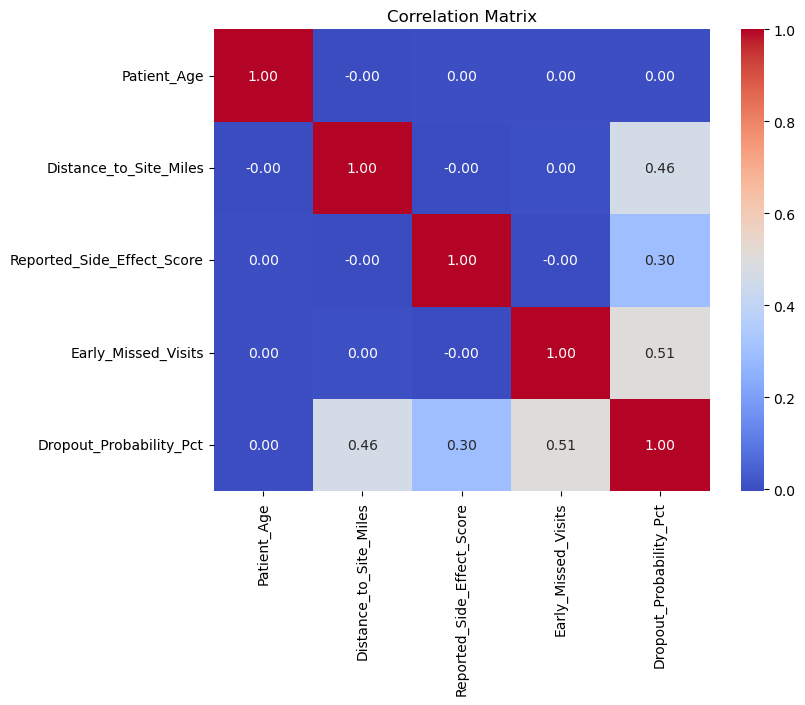

In [8]:
# Correlation Matrix Heatmap

import seaborn as sns

numeric_df = df.select_dtypes(include=["number"])

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [9]:
print("\nInterpretation:")
print("The output shows the correlation between all numerical features in the clinical trial dataset.")
print("Each cell represents the correlation coefficient between two numerical variables.")
print("Correlation values range from -1 to +1.")
print("A value close to +1 indicates a strong positive relationship, meaning both variables increase together.")
print("A value close to -1 indicates a strong negative relationship, meaning one variable increases while the other decreases.")
print("A value close to 0 indicates little or no relationship between the variables.")
print("This correlation matrix helps identify which numerical features are strongly related before training the machine learning model.")


Interpretation:
The output shows the correlation between all numerical features in the clinical trial dataset.
Each cell represents the correlation coefficient between two numerical variables.
Correlation values range from -1 to +1.
A value close to +1 indicates a strong positive relationship, meaning both variables increase together.
A value close to -1 indicates a strong negative relationship, meaning one variable increases while the other decreases.
A value close to 0 indicates little or no relationship between the variables.
This correlation matrix helps identify which numerical features are strongly related before training the machine learning model.


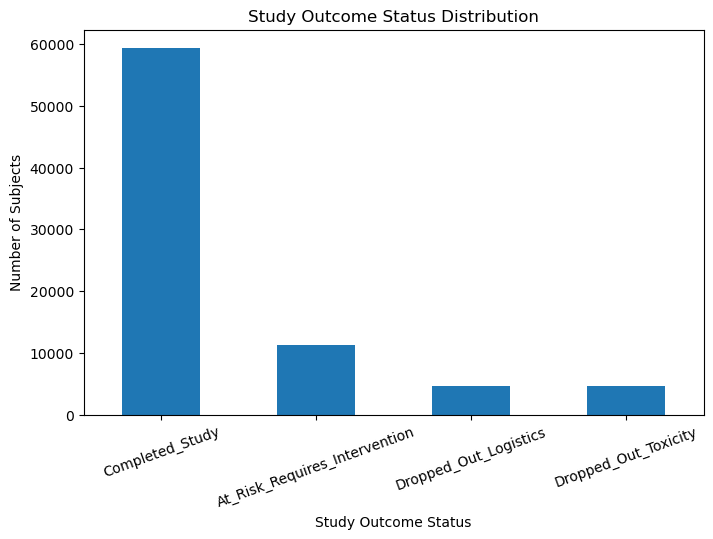

In [10]:
outcome_counts = df["Study_Outcome_Status"].value_counts()

outcome_counts.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Study Outcome Status Distribution")
plt.xlabel("Study Outcome Status")
plt.ylabel("Number of Subjects")
plt.xticks(rotation=20)

plt.show()

In [11]:
print("\nInterpretation:")
print("The output shows the number of subjects in each Study Outcome Status category.")
print("The X-axis represents the different Study Outcome Status categories, and the Y-axis represents the number of subjects.")
print("Each bar indicates how many subjects belong to a particular outcome category.")
print("This graph helps us identify which study outcome has the highest and lowest number of subjects.")
print("It also helps us understand the distribution of the target variable before training the machine learning model.")


Interpretation:
The output shows the number of subjects in each Study Outcome Status category.
The X-axis represents the different Study Outcome Status categories, and the Y-axis represents the number of subjects.
Each bar indicates how many subjects belong to a particular outcome category.
This graph helps us identify which study outcome has the highest and lowest number of subjects.
It also helps us understand the distribution of the target variable before training the machine learning model.


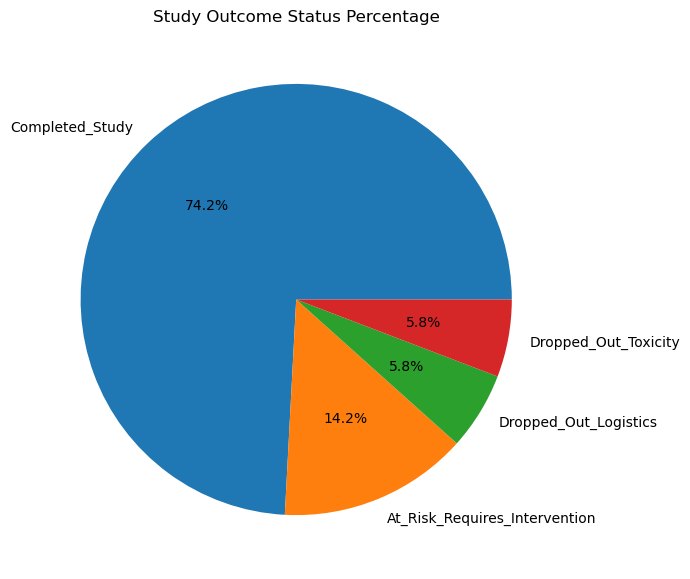

In [12]:
outcome_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7,7)
)

plt.title("Study Outcome Status Percentage")
plt.ylabel("")

plt.show()

In [13]:
print("\nInterpretation:")
print("The output shows the percentage distribution of each Study Outcome Status category.")
print("Each slice of the pie chart represents the proportion of subjects belonging to a particular outcome category.")
print("The percentage displayed on each slice indicates the contribution of that category to the entire dataset.")
print("This graph helps us understand the class distribution and identify whether any outcome category is dominant or underrepresented.")
print("Understanding the target variable distribution is important before training the machine learning model.")


Interpretation:
The output shows the percentage distribution of each Study Outcome Status category.
Each slice of the pie chart represents the proportion of subjects belonging to a particular outcome category.
The percentage displayed on each slice indicates the contribution of that category to the entire dataset.
This graph helps us understand the class distribution and identify whether any outcome category is dominant or underrepresented.
Understanding the target variable distribution is important before training the machine learning model.


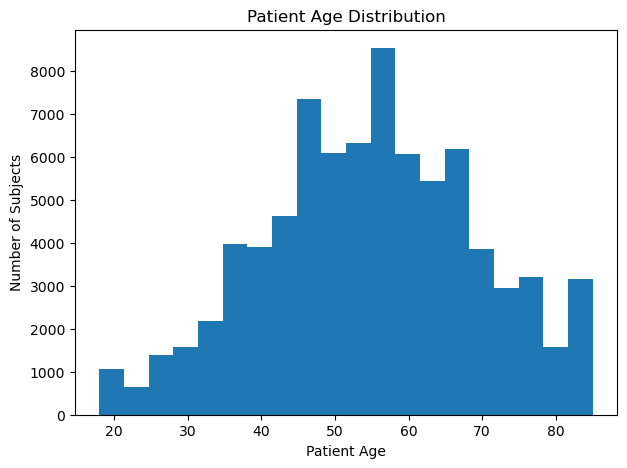

In [14]:
plt.figure(figsize=(7,5))

plt.hist(
    df["Patient_Age"],
    bins=20
)

plt.title("Patient Age Distribution")
plt.xlabel("Patient Age")
plt.ylabel("Number of Subjects")

plt.show()

In [15]:
print("\nInterpretation:")
print("The output shows the distribution of patient ages in the clinical trial dataset.")
print("The X-axis represents the age of the patients, and the Y-axis represents the number of subjects.")
print("Each bar indicates how many subjects belong to a particular age range.")
print("This histogram helps us identify the most common age groups and understand how patient ages are distributed.")
print("It also helps detect whether the ages are evenly distributed or concentrated within specific age ranges before training the machine learning model.")


Interpretation:
The output shows the distribution of patient ages in the clinical trial dataset.
The X-axis represents the age of the patients, and the Y-axis represents the number of subjects.
Each bar indicates how many subjects belong to a particular age range.
This histogram helps us identify the most common age groups and understand how patient ages are distributed.
It also helps detect whether the ages are evenly distributed or concentrated within specific age ranges before training the machine learning model.


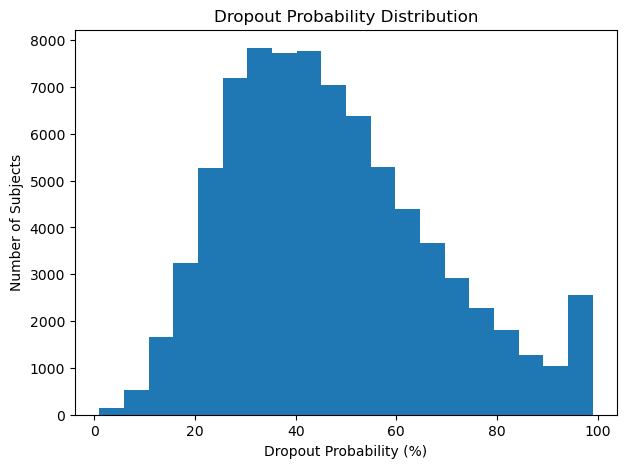

In [16]:
plt.figure(figsize=(7,5))

plt.hist(
    df["Dropout_Probability_Pct"],
    bins=20
)

plt.title("Dropout Probability Distribution")
plt.xlabel("Dropout Probability (%)")
plt.ylabel("Number of Subjects")

plt.show()

In [17]:
print("\nInterpretation:")
print("The output shows the distribution of Dropout Probability (%) for all clinical trial subjects.")
print("The X-axis represents the Dropout Probability (%), and the Y-axis represents the Number of Subjects.")
print("It helps us understand how dropout probabilities are spread across the dataset.")
print("From this histogram, we can identify whether most subjects have low, medium, or high dropout probability.")
print("It also helps detect the overall pattern and concentration of dropout probabilities before training the machine learning model.")


Interpretation:
The output shows the distribution of Dropout Probability (%) for all clinical trial subjects.
The X-axis represents the Dropout Probability (%), and the Y-axis represents the Number of Subjects.
It helps us understand how dropout probabilities are spread across the dataset.
From this histogram, we can identify whether most subjects have low, medium, or high dropout probability.
It also helps detect the overall pattern and concentration of dropout probabilities before training the machine learning model.


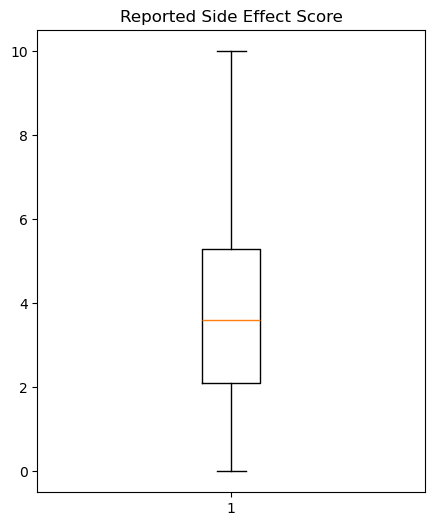

In [18]:
plt.figure(figsize=(5,6))

plt.boxplot(df["Reported_Side_Effect_Score"])

plt.title("Reported Side Effect Score")

plt.show()

In [19]:
print("\nInterpretation:")
print("The output shows the distribution of Reported Side Effect Scores among all clinical trial subjects.")
print("The box plot displays the minimum value, first quartile (Q1), median, third quartile (Q3), and maximum value.")
print("It helps identify the spread of side effect scores and detect any outliers.")
print("A wider spread indicates greater variation in reported side effects among the subjects.")
print("This analysis helps us understand how side effect severity varies across participants before training the machine learning model.")


Interpretation:
The output shows the distribution of Reported Side Effect Scores among all clinical trial subjects.
The box plot displays the minimum value, first quartile (Q1), median, third quartile (Q3), and maximum value.
It helps identify the spread of side effect scores and detect any outliers.
A wider spread indicates greater variation in reported side effects among the subjects.
This analysis helps us understand how side effect severity varies across participants before training the machine learning model.


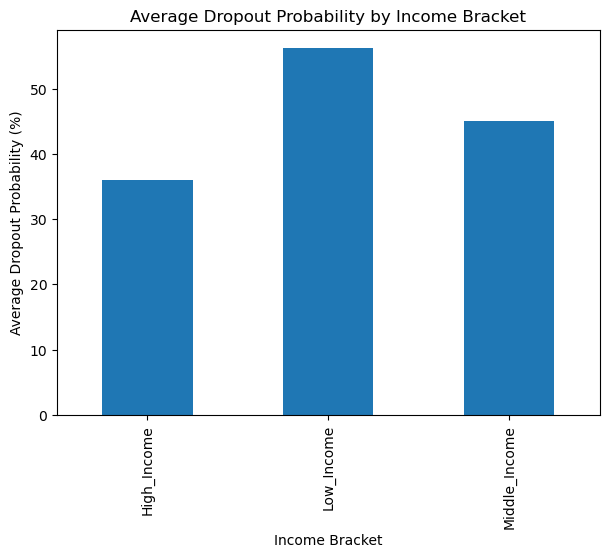

In [20]:
avg_dropout = df.groupby("Income_Bracket")["Dropout_Probability_Pct"].mean()

avg_dropout.plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Average Dropout Probability by Income Bracket")
plt.xlabel("Income Bracket")
plt.ylabel("Average Dropout Probability (%)")

plt.show()

In [21]:
print("\nInterpretation:")
print("The output shows the average Dropout Probability for each Income Bracket.")
print("The X-axis represents the different Income Bracket categories.")
print("The Y-axis represents the Average Dropout Probability (%) for each income group.")
print("This graph helps compare the average risk of dropout among different income levels.")
print("By observing the heights of the bars, we can identify which income bracket has the highest and lowest average dropout probability.")
print("This analysis helps determine whether income level has an influence on the likelihood of participants dropping out of the clinical trial.")


Interpretation:
The output shows the average Dropout Probability for each Income Bracket.
The X-axis represents the different Income Bracket categories.
The Y-axis represents the Average Dropout Probability (%) for each income group.
This graph helps compare the average risk of dropout among different income levels.
By observing the heights of the bars, we can identify which income bracket has the highest and lowest average dropout probability.
This analysis helps determine whether income level has an influence on the likelihood of participants dropping out of the clinical trial.


In [22]:
df = df.drop("Patient_ID", axis=1)

print("Patient_ID column removed successfully.")

Patient_ID column removed successfully.


In [23]:
X = df.drop("Study_Outcome_Status", axis=1)

y = df["Study_Outcome_Status"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (80000, 8)
Target Shape: (80000,)


In [24]:
from sklearn.preprocessing import LabelEncoder

label_encoders = {}

categorical_columns = [
    "Clinical_Site_ID",
    "Therapeutic_Area",
    "Income_Bracket"
]

for column in categorical_columns:

    encoder = LabelEncoder()

    X[column] = encoder.fit_transform(X[column])

    label_encoders[column] = encoder

target_encoder = LabelEncoder()

y = target_encoder.fit_transform(y)

print("Categorical variables encoded successfully.")

Categorical variables encoded successfully.


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (64000, 8)
Testing Features Shape: (16000, 8)
Training Target Shape: (64000,)
Testing Target Shape: (16000,)


In [27]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Balanced Decision Tree model trained successfully!")

Balanced Decision Tree model trained successfully!


In [28]:
y_pred = model.predict(X_test)

print("First 10 Predictions:")
print(y_pred[:10])

First 10 Predictions:
[1 1 1 0 1 2 1 0 0 0]


In [29]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.975125


In [42]:
train_accuracy = model.score(X_train, y_train)
test_accuracy = model.score(X_test, y_test)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

print("\nOverfitting Check:")

if train_accuracy - test_accuracy > 0.05:
    print("There may be some overfitting.")
else:
    print("No major indication of overfitting based on this comparison.")

Training Accuracy: 1.0
Testing Accuracy: 0.975125

Overfitting Check:
No major indication of overfitting based on this comparison.


In [43]:
from sklearn.metrics import classification_report

print("Classification Report")

print(classification_report(y_test, y_pred))

Classification Report
              precision    recall  f1-score   support

           0       0.94      0.96      0.95      2274
           1       0.99      0.99      0.99     11866
           2       0.81      0.74      0.78       931
           3       1.00      1.00      1.00       929

    accuracy                           0.98     16000
   macro avg       0.94      0.92      0.93     16000
weighted avg       0.97      0.98      0.97     16000



In [44]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix")

print(cm)

Confusion Matrix
[[ 2187     0    87     0]
 [    0 11794    72     0]
 [  131   108   692     0]
 [    0     0     0   929]]


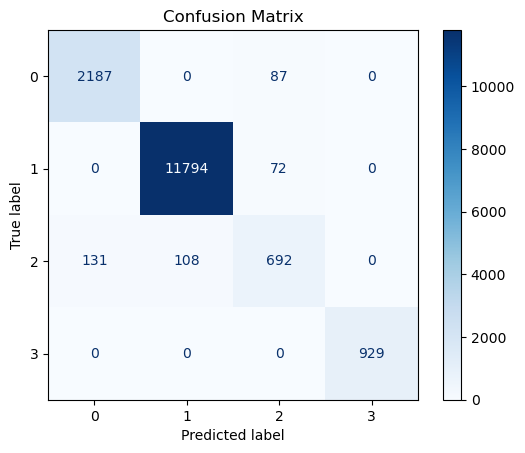

In [45]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix")

plt.show()

In [46]:
print("\nInterpretation:")
print("The output shows the performance of the Decision Tree model by comparing the Actual and Predicted Study Outcome Status.")
print("The rows represent the Actual Study Outcome Status, while the columns represent the Predicted Study Outcome Status.")
print("The diagonal cells indicate the number of correctly classified subjects.")
print("The non-diagonal cells indicate the number of incorrectly classified subjects (misclassifications).")
print("A higher number of values on the diagonal and fewer values outside the diagonal indicate better model performance.")
print("This confusion matrix helps evaluate how accurately the model predicts each Study Outcome Status category.")


Interpretation:
The output shows the performance of the Decision Tree model by comparing the Actual and Predicted Study Outcome Status.
The rows represent the Actual Study Outcome Status, while the columns represent the Predicted Study Outcome Status.
The diagonal cells indicate the number of correctly classified subjects.
The non-diagonal cells indicate the number of incorrectly classified subjects (misclassifications).
A higher number of values on the diagonal and fewer values outside the diagonal indicate better model performance.
This confusion matrix helps evaluate how accurately the model predicts each Study Outcome Status category.


In [47]:
comparison = pd.DataFrame({

    "Actual": target_encoder.inverse_transform(y_test),

    "Predicted": target_encoder.inverse_transform(y_pred)

})

print("Actual vs Predicted")

print(comparison.head(20))

Actual vs Predicted
                           Actual                      Predicted
0                 Completed_Study                Completed_Study
1                 Completed_Study                Completed_Study
2                 Completed_Study                Completed_Study
3   At_Risk_Requires_Intervention  At_Risk_Requires_Intervention
4                 Completed_Study                Completed_Study
5           Dropped_Out_Logistics          Dropped_Out_Logistics
6                 Completed_Study                Completed_Study
7   At_Risk_Requires_Intervention  At_Risk_Requires_Intervention
8   At_Risk_Requires_Intervention  At_Risk_Requires_Intervention
9   At_Risk_Requires_Intervention  At_Risk_Requires_Intervention
10           Dropped_Out_Toxicity           Dropped_Out_Toxicity
11                Completed_Study                Completed_Study
12           Dropped_Out_Toxicity           Dropped_Out_Toxicity
13                Completed_Study                Completed_Study
14   

In [48]:
import joblib

joblib.dump(model, "clinical_trial_attrition_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [49]:
feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": model.feature_importances_

})

feature_importance = feature_importance.sort_values(

    by="Importance",

    ascending=False

)

print("Feature Importance:")

print(feature_importance)

Feature Importance:
                      Feature  Importance
7     Dropout_Probability_Pct    0.623475
4      Distance_to_Site_Miles    0.266870
3              Income_Bracket    0.075969
5  Reported_Side_Effect_Score    0.012418
2                 Patient_Age    0.009289
0            Clinical_Site_ID    0.008248
1            Therapeutic_Area    0.002290
6         Early_Missed_Visits    0.001441


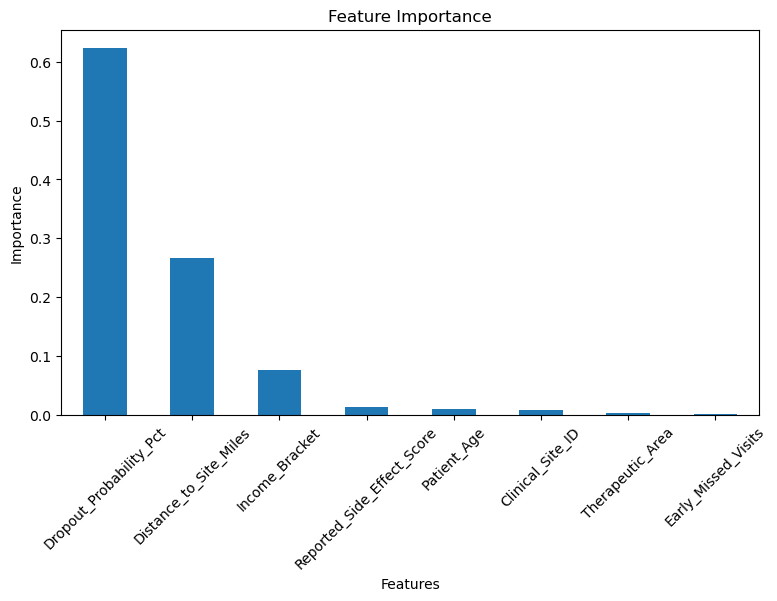

In [50]:
feature_importance.plot(

    x="Feature",

    y="Importance",

    kind="bar",

    figsize=(9,5),

    legend=False

)

plt.title("Feature Importance")

plt.xlabel("Features")

plt.ylabel("Importance")

plt.xticks(rotation=45)

plt.show()

In [51]:
print("\nInterpretation:")
print("The output shows the importance of each feature used by the Decision Tree model for predicting the Study Outcome Status.")
print("The X-axis represents the input features, and the Y-axis represents their importance scores.")
print("Features with higher importance values have a greater influence on the model's predictions.")
print("Features with lower importance values contribute less to the prediction process.")
print("This graph helps identify the most significant factors affecting the Study Outcome Status and improves the understanding of the model.")


Interpretation:
The output shows the importance of each feature used by the Decision Tree model for predicting the Study Outcome Status.
The X-axis represents the input features, and the Y-axis represents their importance scores.
Features with higher importance values have a greater influence on the model's predictions.
Features with lower importance values contribute less to the prediction process.
This graph helps identify the most significant factors affecting the Study Outcome Status and improves the understanding of the model.


In [52]:
new_subject = pd.DataFrame({

    "Clinical_Site_ID": ["CLINIC_24"],

    "Therapeutic_Area": ["Neurology"],

    "Patient_Age": [45],

    "Income_Bracket": ["Middle_Income"],

    "Distance_to_Site_Miles": [20.5],

    "Reported_Side_Effect_Score": [6.5],

    "Early_Missed_Visits": [1],

    "Dropout_Probability_Pct": [72.0]

})

for col in ["Clinical_Site_ID", "Therapeutic_Area", "Income_Bracket"]:

    new_subject[col] = label_encoders[col].transform(new_subject[col])

prediction = model.predict(new_subject)

predicted_status = target_encoder.inverse_transform(prediction)

print("Predicted Study Outcome:")

print(predicted_status[0])

Predicted Study Outcome:
At_Risk_Requires_Intervention


In [53]:
# Predict a Particular Patient

patient_index = 25      # Change this to any patient index

patient = df.iloc[[patient_index]].copy()

# Actual Study Outcome
actual_status = patient["Study_Outcome_Status"].values[0]

# Remove Target Column
patient_features = patient.drop("Study_Outcome_Status", axis=1)

# Encode Categorical Columns
for col in ["Clinical_Site_ID", "Therapeutic_Area", "Income_Bracket"]:
    patient_features[col] = label_encoders[col].transform(patient_features[col])

# Predict
prediction = model.predict(patient_features)

predicted_status = target_encoder.inverse_transform(prediction)

print("Patient Index:", patient_index)
print("Actual Study Outcome :", actual_status)
print("Predicted Study Outcome :", predicted_status[0])

Patient Index: 25
Actual Study Outcome : Completed_Study
Predicted Study Outcome : Completed_Study


In [55]:
print("="*60)

print("PROJECT CONCLUSION")

print("="*60)

print("The Decision Tree model was successfully trained to predict the Study Outcome Status of clinical trial subjects.")

print("The target variable contains four classes, making this a multiclass classification problem.")

print("A significant class imbalance was identified, with Completed Study being the majority class.")

print("To reduce majority-class bias, stratified train-test splitting and class weighting were used during model training.")

print("The model was evaluated using accuracy, classification report, and confusion matrix, with particular attention to the minority dropout classes.")

print("The model can help identify subjects who are likely to complete the study, require intervention, or drop out.")

print("This can help researchers identify at-risk subjects early, improve subject retention, and reduce clinical trial attrition.")

print("="*60)

PROJECT CONCLUSION
The Decision Tree model was successfully trained to predict the Study Outcome Status of clinical trial subjects.
The target variable contains four classes, making this a multiclass classification problem.
A significant class imbalance was identified, with Completed Study being the majority class.
To reduce majority-class bias, stratified train-test splitting and class weighting were used during model training.
The model was evaluated using accuracy, classification report, and confusion matrix, with particular attention to the minority dropout classes.
The model can help identify subjects who are likely to complete the study, require intervention, or drop out.
This can help researchers identify at-risk subjects early, improve subject retention, and reduce clinical trial attrition.
